In [16]:
 # Cell 1 — Install & GPU Check
import subprocess
subprocess.run(["pip", "install", "-q", "keras", "scikit-learn", "joblib", "matplotlib"])

import tensorflow as tf
print("TF version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))


TF version: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [19]:
# Run this FIRST to find correct paths
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/sameer49/sentinel-2/satellite_labels.npy
/kaggle/input/datasets/sameer49/sentinel-2/satellite_images.npy
/kaggle/input/datasets/sameer49/agriyieldprocessed/weather.npy
/kaggle/input/datasets/sameer49/agriyieldprocessed/ndvi.npy
/kaggle/input/datasets/sameer49/agriyieldprocessed/crop_onehot.npy
/kaggle/input/datasets/sameer49/agriyieldprocessed/crop_labels.npy
/kaggle/input/datasets/sameer49/agriyieldprocessed/yields.npy


In [21]:
# Cell 2 — Config (FIXED PATHS)
import os
import numpy as np

# ── Correct Kaggle paths ───────────────────────────────────────────────────
DATA_DIR      = "/kaggle/input/datasets/sameer49/agriyieldprocessed"
SAT_DIR       = "/kaggle/input/datasets/sameer49/sentinel-2"
OUTPUT_DIR    = "/kaggle/working/outputs"
MODEL_DIR     = f"{OUTPUT_DIR}/models"
PLOT_DIR      = f"{OUTPUT_DIR}/plots"
RESULTS_DIR   = f"{OUTPUT_DIR}/results"

for d in [MODEL_DIR, PLOT_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Data ───────────────────────────────────────────────────────────────────
SEQUENCE_LENGTH      = 12
IMAGE_HEIGHT         = 32
IMAGE_WIDTH          = 32
NUM_BANDS            = 5
NUM_WEATHER_FEATURES = 6
NUM_CROPS            = 6

# ── Model ──────────────────────────────────────────────────────────────────
CNN_FILTERS             = [64, 128, 256]
LSTM_UNITS              = [128, 64]
DROPOUT_RATE            = 0.25
LEARNING_RATE           = 5e-4
BATCH_SIZE              = 16
EPOCHS                  = 100
EARLY_STOPPING_PATIENCE = 20
RANDOM_SEED             = 42

# ── Splits ─────────────────────────────────────────────────────────────────
TEST_SPLIT       = 0.15
VALIDATION_SPLIT = 0.15

print("Config ready.")
print("Files found:")
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(" ", os.path.join(dirname, filename))


Config ready.
Files found:
  /kaggle/input/datasets/sameer49/sentinel-2/satellite_labels.npy
  /kaggle/input/datasets/sameer49/sentinel-2/satellite_images.npy
  /kaggle/input/datasets/sameer49/agriyieldprocessed/weather.npy
  /kaggle/input/datasets/sameer49/agriyieldprocessed/ndvi.npy
  /kaggle/input/datasets/sameer49/agriyieldprocessed/crop_onehot.npy
  /kaggle/input/datasets/sameer49/agriyieldprocessed/crop_labels.npy
  /kaggle/input/datasets/sameer49/agriyieldprocessed/yields.npy


In [22]:
# Cell 3 — Load & Split Data (builds images.npy from satellite_images.npy)
import numpy as np

# ── Load satellite images and build images.npy ─────────────────────────────
print("Loading satellite images...")
raw_sat = np.load(f"{SAT_DIR}/satellite_images.npy").astype(np.float32)
print(f"  Raw satellite shape: {raw_sat.shape}")

# Clip to physical ranges [Red,NIR,Blue,Green,SWIR,NDVI,EVI]
CHANNEL_CLIP = [(0,1),(0,1),(0,1),(0,1),(0,1),(-1,1),(-1,1)]
for c, (lo, hi) in enumerate(CHANNEL_CLIP):
    raw_sat[..., c] = np.clip(raw_sat[..., c], lo, hi)

# Normalize each channel to [0, 1]
for c in range(raw_sat.shape[-1]):
    cmin = raw_sat[..., c].min()
    cmax = raw_sat[..., c].max()
    raw_sat[..., c] = (raw_sat[..., c] - cmin) / (cmax - cmin + 1e-8)

images = raw_sat
print(f"  images shape: {images.shape} | min={images.min():.3f} max={images.max():.3f}")

# ── Load remaining processed arrays ───────────────────────────────────────
weather     = np.load(f"{DATA_DIR}/weather.npy")
yields      = np.load(f"{DATA_DIR}/yields.npy")
crop_labels = np.load(f"{DATA_DIR}/crop_labels.npy")
crop_onehot = np.load(f"{DATA_DIR}/crop_onehot.npy")

print(f"weather    : {weather.shape}")
print(f"yields     : {yields.shape} | mean={yields.mean():.3f}")
print(f"crop_onehot: {crop_onehot.shape}")

# ── Split ──────────────────────────────────────────────────────────────────
rng = np.random.default_rng(RANDOM_SEED)
N   = len(yields)
idx = rng.permutation(N)

n_test = int(N * TEST_SPLIT)
n_val  = int(N * VALIDATION_SPLIT)

test_idx  = idx[:n_test]
val_idx   = idx[n_test:n_test + n_val]
train_idx = idx[n_test + n_val:]

def make_split(i):
    return {
        "images":      images[i],
        "weather":     weather[i],
        "yields":      yields[i],
        "crop_labels": crop_labels[i],
        "crop_onehot": crop_onehot[i],
    }

splits = {
    "train": make_split(train_idx),
    "val":   make_split(val_idx),
    "test":  make_split(test_idx),
}

print(f"\nSplit  train:{len(train_idx)}  val:{len(val_idx)}  test:{len(test_idx)}")


Loading satellite images...
  Raw satellite shape: (1200, 12, 32, 32, 7)
  images shape: (1200, 12, 32, 32, 7) | min=0.000 max=1.000
weather    : (1200, 12, 6)
yields     : (1200,) | mean=3.843
crop_onehot: (1200, 6)

Split  train:840  val:180  test:180


In [25]:
# Cell 4 — Feature Engineering & Scalers (FIXED)
import joblib
from sklearn.preprocessing import StandardScaler, MinMaxScaler

def normalize_images(data, fit=True, scaler=None):
    N, T, H, W, C = data.shape
    flat = data.reshape(-1, C)
    if fit:
        scaler = MinMaxScaler()
        flat_s = scaler.fit_transform(flat)
        joblib.dump(scaler, f"{MODEL_DIR}/image_scaler.pkl")
    else:
        flat_s = scaler.transform(flat)
    return flat_s.reshape(N, T, H, W, C).astype(np.float32), scaler

def normalize_weather(data, fit=True, scaler=None):
    N, T, F = data.shape
    flat = data.reshape(-1, F)
    if fit:
        scaler = StandardScaler()
        flat_s = scaler.fit_transform(flat)
        joblib.dump(scaler, f"{MODEL_DIR}/weather_scaler.pkl")
    else:
        flat_s = scaler.transform(flat)
    return flat_s.reshape(N, T, F).astype(np.float32), scaler

def compute_ndvi_stats(image_data):
    red  = image_data[..., 0]
    nir  = image_data[..., 1]
    blue = image_data[..., 2]
    ndvi = (nir - red) / (nir + red + 1e-8)
    spatial_mean = ndvi.mean(axis=(2, 3))
    peak   = spatial_mean.max(axis=1)
    mean   = spatial_mean.mean(axis=1)
    t_axis = np.arange(spatial_mean.shape[1], dtype=np.float32)
    slope  = np.array([np.polyfit(t_axis, spatial_mean[i], 1)[0]
                       for i in range(len(spatial_mean))], dtype=np.float32)
    green_up = spatial_mean.argmax(axis=1).astype(np.float32)
    half     = peak / 2.0
    T        = spatial_mean.shape[1]
    senes    = np.array([next((t for t in range(int(green_up[i]), T)
                               if spatial_mean[i, t] < half[i]), T-1)
                         for i in range(len(spatial_mean))], dtype=np.float32)
    return np.stack([peak, mean, slope, green_up, senes], axis=1)

# ── Fit scalers on full dataset ────────────────────────────────────────────
print("Fitting scalers on full dataset...")
_, img_sc  = normalize_images(images,  fit=True)   # saves image_scaler.pkl
_, wx_sc   = normalize_weather(weather, fit=True)   # saves weather_scaler.pkl

# ── Fit yield scaler ───────────────────────────────────────────────────────
yield_sc = StandardScaler()
yield_sc.fit(yields.reshape(-1, 1))
joblib.dump(yield_sc, f"{MODEL_DIR}/yield_scaler.pkl")
print("All scalers fitted and saved.")

# ── Scale each split ───────────────────────────────────────────────────────
def scale_split(split):
    img_n, _ = normalize_images(split["images"],  fit=False, scaler=img_sc)
    wx_n,  _ = normalize_weather(split["weather"], fit=False, scaler=wx_sc)
    stats    = compute_ndvi_stats(split["images"])
    ml       = np.concatenate([stats, wx_n.reshape(len(stats), -1)], axis=1).astype(np.float32)
    y_sc     = yield_sc.transform(split["yields"].reshape(-1, 1)).flatten().astype(np.float32)
    return img_n, wx_n, ml, y_sc, split["crop_onehot"]

img_tr,  wx_tr,  ml_tr,  y_tr,  crop_tr  = scale_split(splits["train"])
img_val, wx_val, ml_val, y_val, crop_val  = scale_split(splits["val"])
img_te,  wx_te,  ml_te,  y_te,  crop_te  = scale_split(splits["test"])
y_te_raw = splits["test"]["yields"]

print(f"img_tr  : {img_tr.shape}")
print(f"wx_tr   : {wx_tr.shape}")
print(f"ml_tr   : {ml_tr.shape}")
print(f"crop_tr : {crop_tr.shape}")
print(f"y_tr    : {y_tr.shape}  mean={y_tr.mean():.3f}")


Fitting scalers on full dataset...
All scalers fitted and saved.
img_tr  : (840, 12, 32, 32, 7)
wx_tr   : (840, 12, 6)
ml_tr   : (840, 77)
crop_tr : (840, 6)
y_tr    : (840,)  mean=0.020


In [26]:
# Cell 5 — Build Models
import keras
from keras import layers, Model, Input, regularizers

IMG_SHAPE = (SEQUENCE_LENGTH, IMAGE_HEIGHT, IMAGE_WIDTH, NUM_BANDS + 2)
WX_SHAPE  = (SEQUENCE_LENGTH, NUM_WEATHER_FEATURES)

# ── ResNet residual block ──────────────────────────────────────────────────
def residual_block(x, filters, stride=1):
    shortcut = x
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    if shortcut.shape[-1] != filters or stride > 1:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)(shortcut)
    return layers.Add()([x, shortcut])

# ── CNN encoder ───────────────────────────────────────────────────────────
def build_cnn_encoder(input_shape):
    inp = Input(shape=input_shape)
    x = layers.Conv2D(CNN_FILTERS[0], 3, padding="same", use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = residual_block(x, CNN_FILTERS[0])
    x = residual_block(x, CNN_FILTERS[1], stride=2)
    x = residual_block(x, CNN_FILTERS[1])
    x = residual_block(x, CNN_FILTERS[2], stride=2)
    x = residual_block(x, CNN_FILTERS[2])
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(DROPOUT_RATE)(x)
    out = layers.Dense(256, activation="relu")(x)
    return Model(inp, out, name="cnn_encoder")

# ── LSTM encoder ──────────────────────────────────────────────────────────
def build_lstm_encoder(input_shape):
    inp = Input(shape=input_shape)
    x = layers.Masking(mask_value=0.0)(inp)
    x = layers.Bidirectional(
        layers.LSTM(LSTM_UNITS[0], return_sequences=True, dropout=DROPOUT_RATE * 0.5)
    )(x)
    x = layers.LayerNormalization()(x)
    x = layers.Bidirectional(
        layers.LSTM(LSTM_UNITS[1], return_sequences=False, dropout=DROPOUT_RATE * 0.5)
    )(x)
    x = layers.LayerNormalization()(x)
    x = layers.Dropout(DROPOUT_RATE)(x)
    out = layers.Dense(128, activation="relu")(x)
    return Model(inp, out, name="lstm_encoder")

# ── Standalone CNN ────────────────────────────────────────────────────────
def build_standalone_cnn():
    inp = Input(shape=IMG_SHAPE, name="image_input")
    x = layers.TimeDistributed(build_cnn_encoder(IMG_SHAPE[1:]))(inp)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=False))(x)
    x = layers.Dropout(DROPOUT_RATE)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(DROPOUT_RATE * 0.5)(x)
    out = layers.Dense(1, activation="linear", name="yield_output")(x)
    m = Model(inp, out, name="standalone_cnn")
    m.compile(optimizer=keras.optimizers.Adam(5e-4),
              loss=keras.losses.Huber(delta=1.0), metrics=["mae"])
    return m

# ── Standalone LSTM ───────────────────────────────────────────────────────
def build_standalone_lstm():
    inp = Input(shape=WX_SHAPE, name="weather_input")
    x = build_lstm_encoder(WX_SHAPE)(inp)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(DROPOUT_RATE)(x)
    out = layers.Dense(1, activation="linear", name="yield_output")(x)
    m = Model(inp, out, name="standalone_lstm")
    m.compile(optimizer=keras.optimizers.Adam(5e-4),
              loss=keras.losses.Huber(delta=1.0), metrics=["mae"])
    return m

# ── Custom layer for fusion ───────────────────────────────────────────────
@keras.saving.register_keras_serializable()
class SliceChannel(layers.Layer):
    def __init__(self, index, **kwargs):
        super().__init__(**kwargs)
        self.index = index
    def call(self, x):
        return x[:, self.index: self.index + 1]
    def get_config(self):
        return {**super().get_config(), "index": self.index}

# ── Fusion model ──────────────────────────────────────────────────────────
def build_fusion_model():
    reg = regularizers.L2(1e-5)
    lr_schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=LEARNING_RATE,
        decay_steps=EPOCHS * 60,
        alpha=1e-6,
    )

    # CNN branch
    image_inp   = Input(shape=IMG_SHAPE, name="image_input")
    cnn_enc     = build_cnn_encoder(IMG_SHAPE[1:])
    spatial_seq = layers.TimeDistributed(cnn_enc, name="td_cnn")(image_inp)
    cnn_feat    = layers.Bidirectional(
        layers.LSTM(128, return_sequences=False), name="spatial_bilstm"
    )(spatial_seq)
    cnn_proj    = layers.Dense(128, activation="relu",
                               kernel_regularizer=reg, name="cnn_proj")(cnn_feat)

    # LSTM branch
    weather_inp = Input(shape=WX_SHAPE, name="weather_input")
    lstm_feat   = build_lstm_encoder(WX_SHAPE)(weather_inp)
    lstm_proj   = layers.Dense(128, activation="relu",
                               kernel_regularizer=reg, name="lstm_proj")(lstm_feat)

    # Crop embedding
    crop_inp = Input(shape=(NUM_CROPS,), name="crop_input")
    crop_emb = layers.Dense(32, activation="relu",
                            kernel_regularizer=reg, name="crop_emb")(crop_inp)

    # Soft attention gate
    gate_in     = layers.Concatenate(name="gate_concat")([cnn_proj, lstm_proj, crop_emb])
    gate_scores = layers.Dense(2, activation="softmax",
                               use_bias=False, name="gate")(gate_in)
    cnn_w       = SliceChannel(0, name="cnn_weight")(gate_scores)
    lstm_w      = SliceChannel(1, name="lstm_weight")(gate_scores)
    fused       = layers.Add(name="fused")([
        layers.Multiply(name="cnn_attended")([cnn_proj, cnn_w]),
        layers.Multiply(name="lstm_attended")([lstm_proj, lstm_w]),
    ])

    # Regression head
    x = layers.Concatenate(name="head_concat")([fused, crop_emb])
    x = layers.Dense(256, activation="relu",
                     kernel_regularizer=reg, name="head_256")(x)
    x = layers.Dropout(DROPOUT_RATE, name="drop1")(x)
    x = layers.Dense(128, activation="relu",
                     kernel_regularizer=reg, name="head_128")(x)
    x = layers.Dropout(DROPOUT_RATE * 0.5, name="drop2")(x)
    x = layers.Dense(64,  activation="relu",
                     kernel_regularizer=reg, name="head_64")(x)
    out = layers.Dense(1, activation="linear", name="yield_output")(x)

    m = Model(inputs=[image_inp, weather_inp, crop_inp],
              outputs=out, name="fusion_model")
    m.compile(
        optimizer=keras.optimizers.Adam(lr_schedule),
        loss=keras.losses.Huber(delta=1.0),
        metrics=["mae"],
    )
    return m

# ── Quick sanity check ────────────────────────────────────────────────────
print("IMG_SHAPE :", IMG_SHAPE)
print("WX_SHAPE  :", WX_SHAPE)
print("NUM_CROPS :", NUM_CROPS)

fusion_test = build_fusion_model()
print(f"\nFusion model params: {fusion_test.count_params():,}")
del fusion_test
print("\nAll model builders ready. Proceed to Cell 6.")


IMG_SHAPE : (12, 32, 32, 7)
WX_SHAPE  : (12, 6)
NUM_CROPS : 6

Fusion model params: 3,617,889

All model builders ready. Proceed to Cell 6.


In [27]:
# Cell 6 — Train Standalone CNN
from keras.callbacks import EarlyStopping, ModelCheckpoint

cnn_model = build_standalone_cnn()

h_cnn = cnn_model.fit(
    img_tr, y_tr,
    validation_data=(img_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=EARLY_STOPPING_PATIENCE,
                      restore_best_weights=True, verbose=1),
        ModelCheckpoint(f"{MODEL_DIR}/standalone_cnn_best.keras",
                        monitor="val_loss", save_best_only=True, verbose=0),
    ], verbose=1
)
cnn_model.save(f"{MODEL_DIR}/standalone_cnn.keras")
print("Standalone CNN saved.")


Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 45s 270ms/step - loss: 0.4070 - mae: 0.7507 - val_loss: 0.3298 - val_mae: 0.6726
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 207ms/step - loss: 0.2873 - mae: 0.6032 - val_loss: 0.1651 - val_mae: 0.4350
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 202ms/step - loss: 0.1964 - mae: 0.4863 - val_loss: 0.3980 - val_mae: 0.6771
Epoch 4/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 211ms/step - loss: 0.1994 - mae: 0.4877 - val_loss: 0.1383 - val_mae: 0.4269
Epoch 5/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 214ms/step - loss: 0.1935 - mae: 0.4784 - val_loss: 0.1375 - val_mae: 0.3993
Epoch 6/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 208ms/step - loss: 0.1819 - mae: 0.4658 - val_loss: 0.1576 - val_mae: 0.4224
Epoch 7/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 209ms/step - loss: 0.1862 - mae: 0.4661 - val_loss: 0.4367 - val_mae: 0.7944
Epoch 8/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 207ms/step - loss: 0.2147 - mae: 0.5128 - val_loss: 0.1604 - val_mae: 0.4233
Epoch 9/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1

In [28]:
# Cell 7 — Train Standalone LSTM
lstm_model = build_standalone_lstm()

h_lstm = lstm_model.fit(
    wx_tr, y_tr,
    validation_data=(wx_val, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=EARLY_STOPPING_PATIENCE,
                      restore_best_weights=True, verbose=1),
        ModelCheckpoint(f"{MODEL_DIR}/standalone_lstm_best.keras",
                        monitor="val_loss", save_best_only=True, verbose=0),
    ], verbose=1
)
lstm_model.save(f"{MODEL_DIR}/standalone_lstm.keras")
print("Standalone LSTM saved.")


Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss: 0.4959 - mae: 0.8762 - val_loss: 0.3594 - val_mae: 0.7006
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.4230 - mae: 0.7834 - val_loss: 0.3497 - val_mae: 0.6752
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.3824 - mae: 0.7291 - val_loss: 0.3784 - val_mae: 0.7043
Epoch 4/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.3775 - mae: 0.7236 - val_loss: 0.3532 - val_mae: 0.6807
Epoch 7/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.3758 - mae: 0.7158 - val_loss: 0.3479 - val_mae: 0.6701
Epoch 8/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.3784 - mae: 0.7209 - val_loss: 0.3555 - val_mae: 0.6978
Epoch 9/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.3644 - mae: 0.7093 - val_loss: 0.3520 - val_mae: 0.6797
Epoch 10/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.3636 - mae: 0.7053 - val_loss: 0.3583 - val_mae: 0.6947
Epoch 11/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - 

In [30]:
# Cell 8 — Train Fusion Model (main model)
fusion_model = build_fusion_model()
fusion_model.summary()

h_fusion = fusion_model.fit(
    [img_tr, wx_tr, crop_tr], y_tr,
    validation_data=([img_val, wx_val, crop_val], y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=EARLY_STOPPING_PATIENCE,
                      restore_best_weights=True, verbose=1),
        ModelCheckpoint(f"{MODEL_DIR}/fusion_model_best.keras",
                        monitor="val_loss", save_best_only=True, verbose=0),
    ], verbose=1
)
fusion_model.save(f"{MODEL_DIR}/fusion_model.keras")
print("Fusion model saved.")


Model: "fusion_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 12, 32,    │          0 │ -                 │
│ (InputLayer)        │ 32, 7)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ td_cnn              │ (None, 12, 256)   │  2,771,136 │ image_input[0][0] │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ weather_input       │ (None, 12, 6)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_bilstm      │ (None, 256)       │    394,240 │ td_cnn[0][0]      │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_encoder        │ (None, 128)       │    319,872 │ weather_input[0]… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ crop_input          │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_proj (Dense)    │ (None, 128)       │     32,896 │ spatial_bilstm[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_proj (Dense)   │ (None, 128)       │     16,512 │ lstm_encoder[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ crop_emb (Dense)    │ (None, 32)        │        224 │ crop_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_concat         │ (None, 288)       │          0 │ cnn_proj[0][0],   │
│ (Concatenate)       │                   │            │ lstm_proj[0][0],  │
│                     │                   │            │ crop_emb[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate (Dense)        │ (None, 2)         │        576 │ gate_concat[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_weight          │ (None, 1)         │          0 │ gate[0][0]        │
│ (SliceChannel)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_weight         │ (None, 1)         │          0 │ gate[0][0]        │
│ (SliceChannel)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_attended        │ (None, 128)       │          0 │ cnn_proj[0][0],   │
│ (Multiply)          │                   │            │ cnn_weight[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_attended       │ (None, 128)       │          0 │ lstm_proj[0][0],  │
│ (Multiply)          │                   │            │ lstm_weight[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fused (Add)         │ (None, 128)       │          0 │ cnn_attended[0][… │
│                     │                   │            │ lstm_attended[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_concat         │ (None, 160)       │          0 │ fused[0][0],      │
│ (Concatenate)       │                   │            │ crop_emb[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_256 (Dense)    │ (None, 256)       │     41,216 │ head_concat[0][0

 Total params: 3,617,889 (13.80 MB)

 Trainable params: 3,614,817 (13.79 MB)

 Non-trainable params: 3,072 (12.00 KB)

Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 52s 294ms/step - loss: 0.3774 - mae: 0.7123 - val_loss: 0.2844 - val_mae: 0.5960
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 12s 220ms/step - loss: 0.2181 - mae: 0.5063 - val_loss: 0.1332 - val_mae: 0.3733
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 12s 221ms/step - loss: 0.1379 - mae: 0.3909 - val_loss: 0.1098 - val_mae: 0.3324
Epoch 4/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 12s 224ms/step - loss: 0.1129 - mae: 0.3500 - val_loss: 0.0889 - val_mae: 0.3086
Epoch 5/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 12s 226ms/step - loss: 0.1091 - mae: 0.3424 - val_loss: 0.0829 - val_mae: 0.2907
Epoch 6/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 12s 219ms/step - loss: 0.0995 - mae: 0.3275 - val_loss: 0.0857 - val_mae: 0.2933
Epoch 7/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 12s 228ms/step - loss: 0.0994 - mae: 0.3240 - val_loss: 0.0822 - val_mae: 0.3034
Epoch 8/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 216ms/step - loss: 0.0905 - mae: 0.3093 - val_loss: 0.0875 - val_mae: 0.3024
Epoch 9/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 1

KeyboardInterrupt: 

In [31]:
# Cell 9 — Train RF & SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
import joblib

rf = RandomForestRegressor(n_estimators=500, max_features="sqrt",
                           min_samples_leaf=2, random_state=RANDOM_SEED, n_jobs=-1)
rf.fit(ml_tr, y_tr)
joblib.dump(rf, f"{MODEL_DIR}/random_forest.pkl")
print("Random Forest saved.")

svr = SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale")
svr.fit(ml_tr, y_tr)
joblib.dump(svr, f"{MODEL_DIR}/svr.pkl")
print("SVR saved.")


Random Forest saved.
SVR saved.


In [32]:
# Cell 10 — Evaluate All Models
import pandas as pd
from sklearn.metrics import r2_score

def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    rmse  = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    mae   = float(np.mean(np.abs(y_true - y_pred)))
    r2    = float(r2_score(y_true, y_pred))
    smape = float(np.mean(np.abs(y_true - y_pred) /
                  ((np.abs(y_true) + np.abs(y_pred)) / 2.0 + 1e-8)) * 100.0)
    return {"RMSE": rmse, "MAE": mae, "R2": r2, "sMAPE": smape}

def inv(p):
    return yield_sc.inverse_transform(np.array(p).flatten().reshape(-1,1)).flatten()

results = {}

# CNN
pred = inv(cnn_model.predict(img_te, verbose=0).flatten())
results["standalone_cnn"] = compute_metrics(y_te_raw, pred)

# LSTM
pred = inv(lstm_model.predict(wx_te, verbose=0).flatten())
results["standalone_lstm"] = compute_metrics(y_te_raw, pred)

# Fusion
pred = inv(fusion_model.predict([img_te, wx_te, crop_te], verbose=0).flatten())
results["fusion_model"] = compute_metrics(y_te_raw, pred)

# RF
pred = inv(rf.predict(ml_te))
results["random_forest"] = compute_metrics(y_te_raw, pred)

# SVR
pred = inv(svr.predict(ml_te))
results["svr"] = compute_metrics(y_te_raw, pred)

# Print table
print(f"\n{'Model':<22} {'RMSE':>8} {'MAE':>8} {'R²':>8} {'sMAPE%':>9}")
print("=" * 60)
for name, m in results.items():
    print(f"{name:<22} {m['RMSE']:>8.4f} {m['MAE']:>8.4f} {m['R2']:>8.4f} {m['sMAPE']:>9.2f}")

df_results = pd.DataFrame(results).T
df_results.index.name = "Model"
df_results.to_csv(f"{RESULTS_DIR}/all_model_results.csv")
print(f"\nSaved to {RESULTS_DIR}/all_model_results.csv")



Model                      RMSE      MAE       R²    sMAPE%
standalone_cnn           1.6276   1.2279   0.7082     42.99
standalone_lstm          2.8732   2.1415   0.0908     60.53
fusion_model             1.0331   0.7409   0.8824     26.60
random_forest            2.6799   2.1270   0.2090     60.22
svr                      2.7278   2.0328   0.1805     59.25

Saved to /kaggle/working/outputs/results/all_model_results.csv


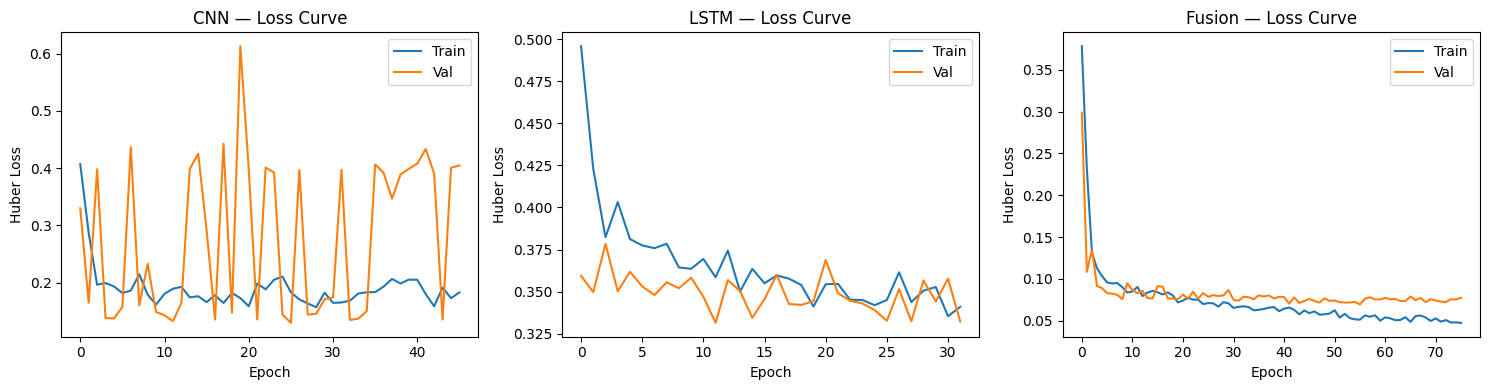

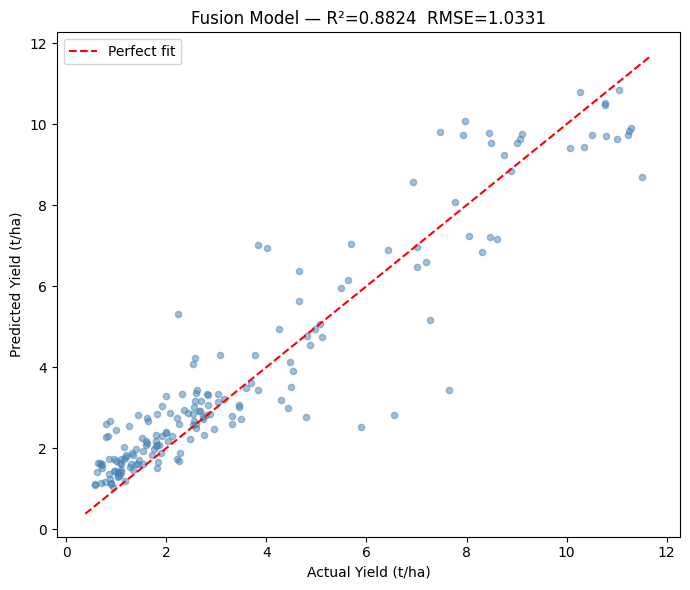

Plots saved.


In [33]:
# Cell 11 — Plots
import matplotlib.pyplot as plt

# Training curves
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, h) in zip(axes, [("CNN", h_cnn), ("LSTM", h_lstm), ("Fusion", h_fusion)]):
    ax.plot(h.history["loss"],     label="Train")
    ax.plot(h.history["val_loss"], label="Val")
    ax.set_title(f"{name} — Loss Curve")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Huber Loss")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/training_curves.png", dpi=150)
plt.show()

# Predicted vs Actual — Fusion
fusion_pred = inv(fusion_model.predict([img_te, wx_te, crop_te], verbose=0).flatten())
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_te_raw, fusion_pred, alpha=0.5, s=20, color="steelblue")
lims = [min(y_te_raw.min(), fusion_pred.min()) - 0.2,
        max(y_te_raw.max(), fusion_pred.max()) + 0.2]
ax.plot(lims, lims, "r--", label="Perfect fit")
ax.set_xlabel("Actual Yield (t/ha)"); ax.set_ylabel("Predicted Yield (t/ha)")
ax.set_title(f"Fusion Model — R²={results['fusion_model']['R2']:.4f}  RMSE={results['fusion_model']['RMSE']:.4f}")
ax.legend()
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/pred_vs_actual_fusion.png", dpi=150)
plt.show()
print("Plots saved.")


In [34]:
# Cell 12 — Zip & Download everything
import shutil
shutil.make_archive("/kaggle/working/agri_yield_outputs", "zip", OUTPUT_DIR)
print("Download: /kaggle/working/agri_yield_outputs.zip")
print("\nFiles inside:")
for root, dirs, files in os.walk(OUTPUT_DIR):
    for f in files:
        path = os.path.join(root, f)
        size = os.path.getsize(path) / 1024
        print(f"  {path.replace(OUTPUT_DIR,'')}  ({size:.1f} KB)")


Download: /kaggle/working/agri_yield_outputs.zip

Files inside:
  /plots/pred_vs_actual_fusion.png  (72.9 KB)
  /plots/training_curves.png  (147.0 KB)
  /results/all_model_results.csv  (0.5 KB)
  /models/fusion_model_best.keras  (71.4 KB)
  /models/yield_scaler.pkl  (0.6 KB)
  /models/fusion_model.keras  (42710.5 KB)
  /models/standalone_lstm_best.keras  (4031.9 KB)
  /models/standalone_cnn_best.keras  (34793.8 KB)
  /models/svr.pkl  (470.9 KB)
  /models/standalone_lstm.keras  (4031.9 KB)
  /models/standalone_cnn.keras  (34793.8 KB)
  /models/random_forest.pkl  (16390.1 KB)
  /models/weather_scaler.pkl  (0.7 KB)
  /models/image_scaler.pkl  (0.8 KB)
